In [ ]:
#import torch
import pandas as pd
import os
import numpy as np
from tensorflow import keras
from tqdm import tqdm
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Softmax, Dropout
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tensorflow.keras.wrappers.scikit_learn import KerasClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from classification_models_1D.tfkeras import Classifiers


In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['CUDA_VISIBLE_DEVICES']='1'
os.environ['WANDB_WATCH'] = 'false'
tensorflow_version = float(tf.__version__[0:3])
import wandb
# Get the GPU memory fraction to allocate
gpu_memory_fraction = 0.8

In [ ]:
data = pd.read_parquet("/media/data1/muse_ge/ECG_ad202207_1453937_cat_labels_original_diagnosis_v1.1.parquet")

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.utils import indexable, _safe_indexing
from sklearn.utils.validation import _num_samples
from sklearn.model_selection._split import _validate_shuffle_split
from itertools import chain


csv_path = "NICM__Data.csv"
NICM_DATA = pd.read_csv(csv_path)

pd.set_option('display.max_columns', None)
# Load the XLSX file)
print(NICM_DATA.shape)
NICM_DATA.head()

(372, 51)


,Unnamed: 0,Correspondance dossier 2,CMD,CMPNI,DOB,Cas index,HTA,DM,IRC,NYHA,AF_msc,age_afmsc,FA,TVNS,date_ECG_NICM,QRS_dur,QRS_bb,Bbloq,ARNI,ACEouARA,ARM,ISGLT-2,Diuretique,Sex,Mutation,Gene,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR01,CMR_LVEF,CMR_LGE,LV_LGE,RVEF,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,DateLFU,DurationFU,AgeatDx,LTVA01,MRN
0,0,NICM1,CMD,yes,1990-07-01 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2018-05-07 00:00:00,92,0,1.0,1.0,0.0,0.0,0.0,0.0,1,0.0,TPM1,p.Lys259Glu,c.775A>G,2018-09-12,2018-07-01 00:00:00,1,44.0,1,0.0,38.0,1.0,1,2018-11-13 00:00:00,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-07-21,5.208219,28.219178,0,544960
1,1,NICM2,CMD,yes,1970-10-14 00:00:00,1,1,0,0,1,0,NaN,0,0.0,2018-07-05 00:00:00,106,0,1.0,1.0,0.0,0.0,0.0,0.0,1,1.0,MYBPC3 + TTN,p.Glu334Lys,c.1000G>A,2015-07-05,2017-01-12 00:00:00,1,43.0,1,1.0,59.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-08-16,5.117808,44.753425,0,536354
2,2,NICM3,CMD,yes,1975-10-03 00:00:00,1,0,0,0,1,0,NaN,0,1.0,2012-12-07 00:00:00,82,0,1.0,1.0,0.0,0.0,0.0,0.0,1,0.0,NaN,NaN,NaN,2012-11-01,2012-12-10 00:00:00,1,29.0,1,0.0,36.0,0.0,NaN,NaN,1,2021-01-12 00:00:00,0,NaN,NaN,0.0,NaN,NaN,2024-03-19,11.287671,37.106849,0,463109
3,3,NICM4,CMD,yes,1955-10-21 00:00:00,1,1,0,0,1,0,NaN,3,1.0,2021-06-01 00:00:00,90,0,1.0,0.0,1.0,0.0,0.0,0.0,1,0.0,LMNA,p.(Arg72His),c.215G>A,2021-06-18,2021-06-25 00:00:00,1,34.0,1,1.0,41.0,1.0,2254,2023-01-06 00:00:00,1,2021-07-09 00:00:00,0,NaN,NaN,0.0,NaN,NaN,2023-01-19,1.635616,65.704110,0,591660
4,4,NICM5,CMD,yes,1948-02-03 00:00:00,1,0,1,0,2,0,NaN,0,1.0,2020-08-19 00:00:00,82,0,1.0,0.0,1.0,0.0,0.0,1.0,1,0.0,NaN,NaN,NaN,2020-06-01,2020-06-01 00:00:00,1,21.0,1,1.0,28.0,1.0,87,2021-07-16 00:00:00,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2024-01-10,3.394521,72.375342,0,575300


In [5]:

csv_path = "/media/data1/mbahani/NICM_withCRTstatus.xlsx"
NICM_withCRT = pd.read_excel(csv_path)
pd.set_option('display.max_columns', None)
# Load the XLSX file)
print(NICM_withCRT.shape)
NICM_withCRT.head()
NICM_withCRT__ =  NICM_withCRT[[NICM_withCRT.columns[0],NICM_withCRT.columns[-1]]]
print(NICM_withCRT__.shape)

(431, 62)
(431, 2)


In [6]:
NICM_withCRT__.head()
NICM_DATA = pd.merge(NICM_DATA, NICM_withCRT__, left_on='Correspondance dossier 2', right_on='correspondance', how='left')

In [7]:
fam_ecg = NICM_DATA["MRN"].values.tolist()
fam_ecg = list(map(str,fam_ecg))
#data['RestingECG_PatientDemographics_PatientID'] = [str(i).replace("'","") for i in data['RestingECG_PatientDemographics_PatientID'].tolist()]
#data['RestingECG_PatientDemographics_PatientID'] = [str(i).zfill(7) for i in data['RestingECG_PatientDemographics_PatientID'].tolist()]
#data['RestingECG_PatientDemographics_PatientID'] = data['RestingECG_PatientDemographics_PatientID'].str.strip()

fam_ecg = [x.zfill(7) for x in fam_ecg]

# Now try creating the subset
data_ = data.loc[data['RestingECG_PatientDemographics_PatientID'].isin(fam_ecg)]
data_.shape


(4677, 583)

In [ ]:
import pickle
#with open('NICM_Test_ids_list.pkl', 'wb') as f:pickle.dump(ids_test, f) #ids_test.append("0315104")ids_test.append("0320362")
with open('NICM_Test_ids_list.pkl', 'rb') as file:
    ids_test = pickle.load(file)

ids_test = [str(x).zfill(7) for x in ids_test[:-2]]

test_data_ = data_.loc[data_['RestingECG_PatientDemographics_PatientID'].isin(ids_test)]

train_data_ = data_.loc[~data_['RestingECG_PatientDemographics_PatientID'].isin(ids_test)]

(3874, 53)


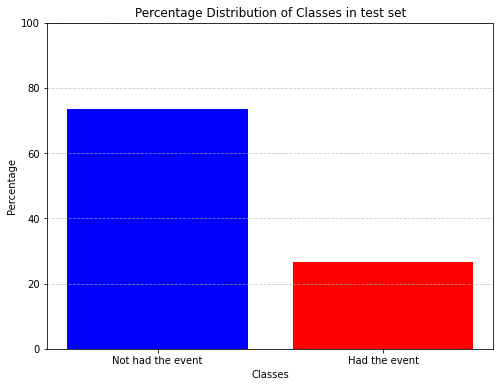

In [10]:
train_label = []
test_label = []

Train_feature = []

Test_feature = []
sub_set_ID = train_data_["RestingECG_PatientDemographics_PatientID"].values.tolist()
for patient_ID in  sub_set_ID:
    Train_feature.append(NICM_DATA.loc[NICM_DATA['MRN'] == int(patient_ID), :].values.flatten())

sub_set_ID = test_data_["RestingECG_PatientDemographics_PatientID"].values.tolist()
for patient_ID in  sub_set_ID:
    Test_feature.append(NICM_DATA.loc[NICM_DATA['MRN'] == int(patient_ID), :].values.flatten())
Train_feature = pd.DataFrame(Train_feature, columns=NICM_DATA.columns)
Test_feature = pd.DataFrame(Test_feature, columns=NICM_DATA.columns)


train_CV = Train_feature
print(train_CV.shape)
train_CV.head()
train_label = train_CV["LTVA01"].values.tolist()
test_label = Test_feature["LTVA01"].values.tolist()

import matplotlib.pyplot as plt
test_label = train_label
# Example data (replace this with your actual data)
class_labels = ['Not had the event', 'Had the event']
class_percentages = [100*(test_label.count(0)/len(test_label)), 100*(test_label.count(1)/len(test_label))]  # Percentage of each class

# Plotting the histogram
plt.figure(figsize=(8, 6))
plt.bar(class_labels, class_percentages, color=['blue', 'red'])
plt.xlabel('Classes')
plt.ylabel('Percentage')
plt.title('Percentage Distribution of Classes in test set')
plt.ylim(0, 100)  # Set y-axis limits from 0 to 100 (assuming percentages)
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add gridlines
plt.show()


In [11]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

test_cv = Test_feature 

training_file_path = train_data_["npy_path"].values.tolist()
test_images_path = test_data_["npy_path"].values.tolist()


train_CV["npy_path"] = training_file_path 
test_cv["npy_path"] = test_images_path

train_CV["Age"] = train_data_["RestingECG_PatientDemographics_PatientAge"].values.tolist()
test_cv["Age"] = test_data_["RestingECG_PatientDemographics_PatientAge"].values.tolist()
train_CV['Age'] = scaler.fit_transform(train_CV[['Age']])
test_cv['Age'] = scaler.fit_transform(test_cv[['Age']])

train_CV.shape

(3874, 55)

In [12]:
test_cv["RestingECG_TestDemographics_AcquisitionDate"] = [str(j) for j in test_data_["RestingECG_TestDemographics_AcquisitionDate"]]
test_cv["RestingECG_TestDemographics_AcquisitionDate"] =  [str(i).replace("00:00:00","") for i in test_cv["RestingECG_TestDemographics_AcquisitionDate"].values.tolist()]
test_cv['RestingECG_TestDemographics_AcquisitionDate'] = pd.to_datetime(test_cv['RestingECG_TestDemographics_AcquisitionDate'])
test_cv["date_ECG_NICM"] = [str(j).replace("00:00:00","").replace("//","/").replace("/","-") for j in test_cv["date_ECG_NICM"]]
test_cv['date_ECG_NICM'] = pd.to_datetime(test_cv['date_ECG_NICM'])
test_cv['date_crt'] = pd.to_datetime(test_cv['date_crt'])

test_cv.head()

,Unnamed: 0,Correspondance dossier 2,CMD,CMPNI,DOB,Cas index,HTA,DM,IRC,NYHA,AF_msc,age_afmsc,FA,TVNS,date_ECG_NICM,QRS_dur,QRS_bb,Bbloq,ARNI,ACEouARA,ARM,ISGLT-2,Diuretique,Sex,Mutation,Gene,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR01,CMR_LVEF,CMR_LGE,LV_LGE,RVEF,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,DateLFU,DurationFU,AgeatDx,LTVA01,MRN,correspondance,date_crt,npy_path,Age,RestingECG_TestDemographics_AcquisitionDate
0,107,NICM122,CMD,yes,1962-06-09 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2020-06-03,104,0,1.0,0.0,1.0,1.0,0.0,1.0,1,1.0,TTN,NaN,NaN,2019-11-01,2020-06-09 00:00:00,1,21.0,1,1.0,34.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-04-05,2.838356,57.435616,0,113058,NICM122,NaT,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.677419,2020-07-24
1,107,NICM122,CMD,yes,1962-06-09 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2020-06-03,104,0,1.0,0.0,1.0,1.0,0.0,1.0,1,1.0,TTN,NaN,NaN,2019-11-01,2020-06-09 00:00:00,1,21.0,1,1.0,34.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-04-05,2.838356,57.435616,0,113058,NICM122,NaT,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.677419,2020-06-11
2,107,NICM122,CMD,yes,1962-06-09 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2020-06-03,104,0,1.0,0.0,1.0,1.0,0.0,1.0,1,1.0,TTN,NaN,NaN,2019-11-01,2020-06-09 00:00:00,1,21.0,1,1.0,34.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-04-05,2.838356,57.435616,0,113058,NICM122,NaT,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.677419,2020-06-10
3,107,NICM122,CMD,yes,1962-06-09 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2020-06-03,104,0,1.0,0.0,1.0,1.0,0.0,1.0,1,1.0,TTN,NaN,NaN,2019-11-01,2020-06-09 00:00:00,1,21.0,1,1.0,34.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-04-05,2.838356,57.435616,0,113058,NICM122,NaT,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.661290,2020-06-07
4,107,NICM122,CMD,yes,1962-06-09 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2020-06-03,104,0,1.0,0.0,1.0,1.0,0.0,1.0,1,1.0,TTN,NaN,NaN,2019-11-01,2020-06-09 00:00:00,1,21.0,1,1.0,34.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-04-05,2.838356,57.435616,0,113058,NICM122,NaT,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.677419,2020-06-09


In [13]:
import pandas as pd
from datetime import datetime
today_date = pd.to_datetime(datetime.now().date())

# Define a function to sort each group by the nearest date to today
def sort_by_nearest_date(group):
    return group.assign(
        distance_to_today=abs(group['RestingECG_TestDemographics_AcquisitionDate'] - today_date)
    ).sort_values(by='distance_to_today').drop(columns='distance_to_today')

# Sort each group by the nearest date to today using groupby and apply
sorted_df = test_cv.groupby('MRN', group_keys=False).apply(sort_by_nearest_date)

# Reset index after sorting
sorted_df.reset_index(drop=True, inplace=True)

In [14]:
import pandas as pd
import datetime

def convert_excel_date(excel_date):
    try:
        # Check if the value is a number (Excel date)
        temp = datetime.datetime(1899, 12, 30)  # Correct base date
        delta = datetime.timedelta(days=int(float(excel_date)))
        converted_date = temp + delta
        return converted_date.strftime("%Y-%m-%d")
    except (ValueError, TypeError):
        # If conversion fails, return the original value (assuming it's a string date)
        return excel_date

# Apply conversion function
sorted_df["DateLTVAafterDx"] = [convert_excel_date(j) if not pd.isnull(j) else j for j in sorted_df["DateLTVAafterDx"]]

# Convert all dates to datetime format
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')

# Ensure all dates are in a consistent format
sorted_df["DateLTVAafterDx"] = sorted_df["DateLTVAafterDx"].dt.strftime("%Y-%m-%d")

# Convert back to datetime for date comparison
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')



In [15]:
import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['DateLTVAafterDx']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) > abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = sorted_df[sorted_df.apply(nearest_to_today, axis=1)]

In [16]:
import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today__(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['date_ECG_NICM']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) < abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = filtered_df[filtered_df.apply(nearest_to_today__, axis=1)]

In [17]:
def nearest_to_today__(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['date_crt']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) > abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = filtered_df[filtered_df.apply(nearest_to_today__, axis=1)]

In [18]:
print(filtered_df.shape)
test_cv = filtered_df

(422, 56)


In [19]:
import numpy as np
from tensorflow.keras.utils import Sequence

class DataGenerator(Sequence):
    def __init__(self, x_ecg, x_numerical, y_set, batch_size, shuffle=True):
        self.x_ecg, self.x_numerical, self.y = x_ecg, x_numerical, y_set
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.x_ecg))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __len__(self):
        return int(np.ceil(len(self.x_ecg) / float(self.batch_size)))

    def __getitem__(self, idx):
        start_idx = idx * self.batch_size
        end_idx = (idx + 1) * self.batch_size

        batch_indices = self.indexes[start_idx:end_idx]
        batch_x_ecg = self.x_ecg[batch_indices].astype(np.float32)
        batch_x_numerical = self.x_numerical[batch_indices].astype(np.float32)
        batch_y = self.y[batch_indices].astype(np.float32)

        return [batch_x_ecg, batch_x_numerical], batch_y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)


In [20]:
class DataGeneratorECG(Sequence):
    def __init__(self, x_set, y_set, batch_size, shuffle=True):
        self.x, self.y = x_set, y_set
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.x))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __len__(self):
        return int(np.ceil(len(self.x) / float(self.batch_size)))

    def __getitem__(self, idx):
        start_idx = idx * self.batch_size
        end_idx = (idx + 1) * self.batch_size

        batch_indices = self.indexes[start_idx:end_idx]
        batch_x = self.x[batch_indices].astype(np.float32)
        batch_y = self.y[batch_indices].astype(np.float32)

        return batch_x, batch_y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

In [29]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
          ecg = np.load(f)
          a,b,c = ecg.shape
          scaler.fit(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = scaler.transform(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = np.squeeze(ecg.reshape((c,a,b)))

    return ecg


trainCV_ECG_path = train_CV["npy_path"].values.tolist()
trainCV_data = np.empty([len(trainCV_ECG_path),2500,12])
for i, path in tqdm(enumerate(trainCV_ECG_path)):
     trainCV_data[i,:,:] = load_and_preprocess_ecg(path)


test_ECG_path = test_cv["npy_path"].values.tolist()
test___data = np.empty([len(test_ECG_path),2500,12])
for i, path in tqdm(enumerate(test_ECG_path)):
     test___data[i,:,:] = load_and_preprocess_ecg(path)


0it [00:00, ?it/s]

In [21]:
trainCV_data = np.load("trainCV_data.npy")
test___data = np.load("test___data.npy")

In [27]:
np.save("test___data.npy",test___data)
np.save("trainCV_data.npy",trainCV_data)
print(test___data.shape)

(422, 2500, 12)


In [22]:
from numpy import float32



col = ["Age"]#"ICD_0",
test_features = np.array(test_cv[col].values,dtype= np.float32)

TrainCV_features = np.array(train_CV[col].values,dtype= np.float32)


In [23]:
y_train = train_CV["LTVA01"]

y_test = test_cv["LTVA01"]
y_train, y_test =  np.array(y_train, dtype= np.float32), np.array(y_test, dtype= np.float32)



In [24]:

import numpy as np

def to_one_hot(vector):
    # Find unique classes
    classes = np.unique(vector)

    # Create one-hot encoded matrix
    one_hot_test = np.zeros((vector.size, classes.size))

    # Fill in the one-hot matrix
    for i, val in enumerate(vector):
        class_index = np.where(classes == val)[0][0]
        one_hot_test[i, class_index] = 1
    return one_hot_test

one_hot_test = to_one_hot(y_test)
one_hot_train = to_one_hot(y_train)



In [25]:
loss=tf.keras.losses.BinaryFocalCrossentropy( gamma=2, from_logits=True)
def custom_loss_with_regularization(y_true, y_pred,loss_function = loss):
    # Binary crossentropy loss
    binary_crossentropy_loss = loss_function(y_true, y_pred)
        # L1 and L2 regularization terms
    l1_regularization = 0.0001  # Adjust the regularization strength as needed
    l2_regularization = 0.0001  # Adjust the regularization strength as needed

    # Get all trainable weights in the model
    trainable_weights = model.trainable_weights

    # Calculate L1 regularization term
    l1_loss = tf.add_n([tf.reduce_sum(tf.abs(w)) for w in trainable_weights])

    # Calculate L2 regularization term
    l2_loss = tf.add_n([tf.reduce_sum(tf.square(w)) for w in trainable_weights])

    # Add regularization terms to the loss
    total_loss = binary_crossentropy_loss + l1_regularization * l1_loss + l2_regularization * l2_loss

    return total_loss

In [ ]:

#test_dataset = DataGenerator(test___data, np.array(y_test).astype(np.float32), batch_size=256, shuffle=False)

col = ["Age"]#,#,,
t_features = np.array(test_cv[col].values,dtype= np.float32)
test_dataset_ecg_with_vars = DataGenerator(test___data, t_features,np.array(y_test).astype(np.float32), batch_size=256, shuffle=False)
# Replace 'pretrain_models/model_Resnet_50__With_Vars_AUC0.7083233284962122.h5' with the actual path to your saved model
#model_path = 'pretrain_models/model_Resnet_50__With_Vars_AUC0.7083233284962122.h5'

# Load the model
model_path = 'Models/model_Resnet_50_ecg_With_Vars.h5'
#model_path = "Models/model_Resnet_50__With_Vars_AUC0.7428947591947677_V2.h5"


loaded_model_ecg_with_var = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})

predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)




2024-07-18 14:21:48.313149: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:39] Overriding allow_growth setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.


2/2 [==============================] - 12s 1s/step


In [ ]:
test_dataset_ecg = DataGeneratorECG(test___data, np.array(y_test).astype(np.float32), batch_size=256, shuffle=False)

model_path = 'pretrain_models/model_Resnet_50_ecg.h5'

# Load the model and provide the custom loss function in the custom_objects parameter
loaded_model_ecg = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})
predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

2/2 [==============================] - 2s 24ms/step


Confusion Matrix:


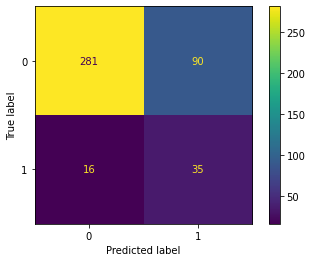


Classification Report:
              precision    recall  f1-score   support

         0.0       0.95      0.76      0.84       371
         1.0       0.28      0.69      0.40        51

    accuracy                           0.75       422
   macro avg       0.61      0.72      0.62       422
weighted avg       0.87      0.75      0.79       422


Sensitivity (Recall): 0.6863
Specificity: 0.7574

 PPV : 0.2800
NPV : 0.9461


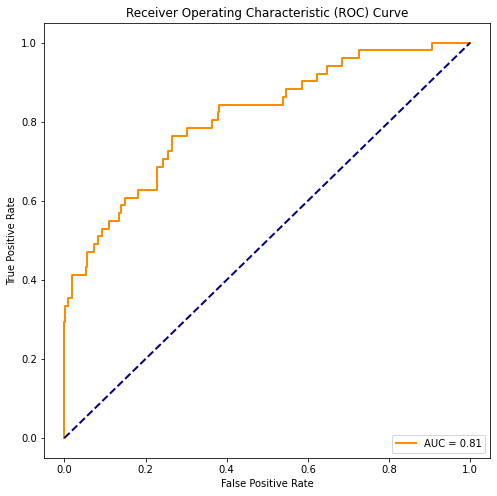

In [35]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, auc, classification_report,ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def plot_results(predictions, test_label = test_label):
    binary_predictions = (predictions > 0.01).astype(int)
    #binary_predictions = predictions
    cm = confusion_matrix(test_label, binary_predictions)
    print("Confusion Matrix:")
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()

    plt.show()

    # Classification Report
    print("\nClassification Report:")
    print(classification_report(test_label, binary_predictions))

    # Calculate Sensitivity (Recall) and Specificity
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    ppv = tp / (tp + fp)
    npv = tn / (tn + fn)

    print(f"\nSensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"\n PPV : {ppv:.4f}")
    print(f"NPV : {npv:.4f}")

    # Calculate ROC Curve and AUC
    fpr, tpr, thresholds = roc_curve(test_label, predictions)
    roc_auc = auc(fpr, tpr)

    # Plot ROC Curve
    plt.figure(figsize=(8, 8))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'AUC = {roc_auc:.2f}')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.show()
plot_results(pro_prediction,test_label= y_test)

In [28]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score
from joblib import dump, load

threshold = 0.5
#X_rf = test_cv[test_cv.columns[4:13]] # 94 0.69
#clf_rf = load('dataset/random_forest_classifier.joblib')
#rf_prediction = clf_rf.predict_proba(X_rf)[:, 1]

def pred_final(predictions_ECG=predictions_ECG, predictions_ECG_with_Var=predictions_ECG_with_Var, weights = [0.50,0.50]):

    #rf_prediction_ = np.expand_dims(rf_prediction, axis=1)
    predictions_ECG_ = [i[0] for i in predictions_ECG]
    predictions_ECG_with_Var_ = [i[0] for i in predictions_ECG_with_Var]
    #rf_prediction_ = [i[0] for i in rf_prediction_] 
    
    final_prediction = []
    for i in range(len(predictions_ECG_)):
        s = weights[0]*predictions_ECG_[i]+ weights[1]* predictions_ECG_with_Var_[i] #+ weights[0]*rf_prediction_[i]
        final_prediction.append(s)
    pro_prediction = np.array(final_prediction)
    return pro_prediction

threshold = 0.2
pro_prediction = pred_final()
final_prediction_ = ( pro_prediction>= threshold).astype(int)
accuracy_voting = accuracy_score(y_test, final_prediction_)

print("Ensemble  Classifier Accuracy:", accuracy_voting)

Ensemble  Classifier Accuracy: 0.9075829383886256


In [29]:
zero_index = []
one_index = []
zero_age = []
one_age = []

for i in range(len(final_prediction_)):
    if  final_prediction_[i]== y_test[i] and final_prediction_[i]== 1:
        one_index.append(i)
        one_age.append(t_features[i])

    if  final_prediction_[i]== y_test[i] and final_prediction_[i]== 0:
        zero_index.append(i)
        zero_age.append(t_features[i])


In [30]:
zero_ecg =  test___data[zero_index]
one_ecg =  test___data[one_index]

In [55]:
import neurokit2 as nk
from scipy.signal import resample
import numpy as np
import tensorflow as tf
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt

# Function to get RR interval
def get_rr_interval(ecg, sampling_rate=250):
    try:
        # Detect R-peaks
        _, rpeaks = nk.ecg_peaks(ecg, sampling_rate=sampling_rate)
        rpeak_indices = rpeaks['ECG_R_Peaks']
        
        # Select the first R-R interval (if multiple R-peaks are found)
        if len(rpeak_indices) > 1:
            return ecg[rpeak_indices[0]:rpeak_indices[1]]
        else:
            return None
    except Exception as e:
        # Return None if no R-peaks are found or an error occurs
        return None
def pre_ecg(one_ecg):
    # Initialize the final ECG array
    ecg_of_one_final = np.empty([2500, 12])

    for i in range(12):
        lead_ecgs = one_ecg[:, :, i]
        rr_intervals = [get_rr_interval(ecg) for ecg in lead_ecgs]
        rr_intervals = [interval for interval in rr_intervals if interval is not None]
        normalized_rr_intervals = [resample(interval, 250) for interval in rr_intervals]

        # Concatenate the normalized RR intervals to form a single array of length 2500
        concatenated_intervals = np.concatenate(normalized_rr_intervals)
        
        # Ensure the concatenated array is of length 2500
        if len(concatenated_intervals) > 2500:
            concatenated_intervals = concatenated_intervals[:2500]
        elif len(concatenated_intervals) < 2500:
            concatenated_intervals = np.pad(concatenated_intervals, (0, 2500 - len(concatenated_intervals)), 'constant')

        # Store in the final ECG array
        ecg_of_one_final[:, i] = concatenated_intervals
    #ecg_of_one_final = np.expand_dims(ecg_of_one_final,axis=0)
    return ecg_of_one_final
ecg_of_one_final = pre_ecg(one_ecg)
zero_ecg_final = pre_ecg(zero_ecg)
print(ecg_of_one_final.shape)  # Should print (2500, 12)

(2500, 12)


In [ ]:

def predict_function(ecg_data,label=1):
    if label == 1:
        ecg_data_reshaped =ecg_data.reshape(ecg_data.shape[0], 2500, 12)  # Reshape to (batch_size, 2500, 12)
        test_dataset = DataGeneratorECG(ecg_data_reshaped, np.ones((ecg_data_reshaped.shape[0], 1)).astype(np.float32), batch_size=1, shuffle=False)
    
    else:
        ecg_data_reshaped = ecg_data.reshape(ecg_data.shape[0], 2500, 12)  # Reshape to (batch_size, 2500, 12)
        test_dataset = DataGeneratorECG(ecg_data_reshaped, np.zeros((ecg_data_reshaped.shape[0], 1)).astype(np.float32), batch_size=1, shuffle=False)
    model_path = 'pretrain_models/model_Resnet_50_ecg.h5'
    loaded_model_ecg = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})  
    prs = loaded_model_ecg.predict(test_dataset, verbose=0)  
    pr = prs[0]
    vl = pr[0]
    pr = np.array([[1-vl,vl]])
    return pr


In [33]:
pr= predict_function(ecg_of_one_final,label=1)
pr

array([[0.00506753, 0.99493247]])

In [56]:
import numpy as np
import tensorflow as tf
from sklearn.linear_model import LinearRegression

def generate_perturbations(data, num_samples=500):
    """
    Generate perturbed versions of the input data.
    """
    perturbed_data = np.random.normal(data, 0.01, size=(num_samples, *data.shape))
    return perturbed_data

def lime_explanation(model, data, num_samples=500, pool_channels=True,channels = False):
    """
    Explain a prediction using LIME for multivariate time series data.

    Args:
    - model: The TensorFlow model to explain.
    - data: The input data instance to explain, shaped as (1, time_steps, channels).
    - num_samples: Number of samples to generate for the explanation.
    - pool_channels: Whether to pool explanations across channels or not.

    Returns:
    - Coefficients indicating feature importance, shaped as (channels,) or a single value if pooled.
    """
    # Generate perturbed data samples
    perturbed_data = generate_perturbations(data, num_samples)
    original_shape = perturbed_data.shape[1:]

    # Predict using the original model
    predictions = model.predict(perturbed_data).flatten()

    # Fit a linear model for each channel if not pooling, else pool data
    if pool_channels:
        # Pooling perturbed data across channels
        perturbed_data_pooled = perturbed_data.reshape(num_samples, -1)
        linear_model = LinearRegression()
        linear_model.fit(perturbed_data_pooled, predictions)
        coefficients = linear_model.coef_.reshape(original_shape).mean(axis=0)  # Mean importance across all channels
    else:
        coefficients = {}  # Channels
        for channel in range(original_shape[1]):
            # Selecting data for the current channel
            channel_data = perturbed_data[:, :, channel].reshape(num_samples, -1)
            linear_model = LinearRegression()
            linear_model.fit(channel_data, predictions)
            #print(len(linear_model.coef_))
            if channels:
                coefficients[channel] = linear_model.coef_.mean() 
            else:
                coefficients[channel] = linear_model.coef_

            

    return coefficients

# Example usage:
# model = ...  # Your 1D CNN model
# input_data = ...  # Your input data here, shaped (1, 2500, 12) for a single instance
# pred_index = None  # Optional: class to visualize (None for the highest prediction)

#ecg_of_one_final = np.squeeze(ecg_of_one_final, axis=0)



# For individual channel explanations
# channel_coefficients = lime_explanation(model, input_data, pool_channels=False)
# print("Channel-specific coefficients:", channel_coefficients)

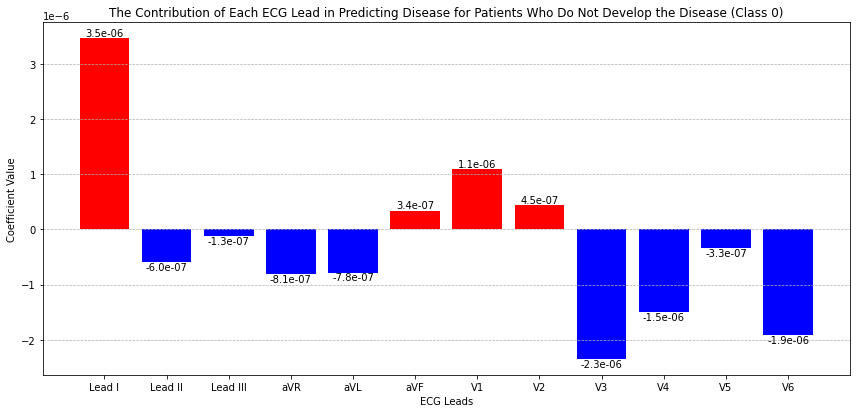

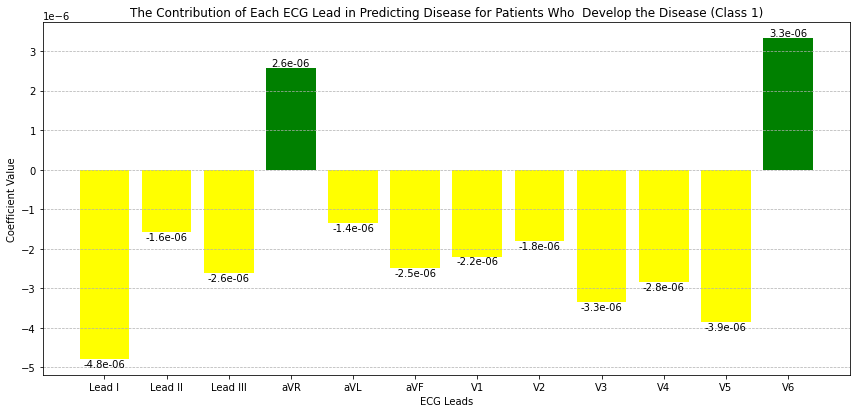

In [60]:
pooled_coefficients = lime_explanation(model= loaded_model_ecg, data = zero_ecg_final, pool_channels=False,channels=True)
def plot_leads(pooled_coefficients,class_ = 0):
     if class_ == 0:
          title = "The Contribution of Each ECG Lead in Predicting Disease for Patients Who Do Not Develop the Disease (Class 0)"
     else:
          title = "The Contribution of Each ECG Lead in Predicting Disease for Patients Who  Develop the Disease (Class 1)"

     lead_names = ["Lead I", "Lead II", "Lead III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

     # Extracting leads and their corresponding coefficients
     leads = list(pooled_coefficients.keys())
     coeff_values = list(pooled_coefficients.values())

     # Plotting
     plt.figure(figsize=(12, 6))
     bars = plt.bar(leads, coeff_values, color=['blue' if val < 0 else 'red' for val in coeff_values])

     # Adding annotations
     plt.xlabel('ECG Leads')
     plt.ylabel('Coefficient Value')
     plt.title(title)
     plt.xticks(leads, lead_names)

     # Highlighting positive and negative coefficients with different colors
     for bar, value in zip(bars, coeff_values):
          height = bar.get_height()
          if height < 0:
               plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.1e}', ha='center', va='top')
          else:
               plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.1e}', ha='center', va='bottom')

     plt.grid(axis='y', linestyle='--', linewidth=0.7)
     plt.tight_layout()
     plt.show()
plot_leads(pooled_coefficients)

pooled_coefficients = lime_explanation(model= loaded_model_ecg, data = ecg_of_one_final, pool_channels=False,channels=True)
def plot_leads(pooled_coefficients,class_ = 1):
     if class_ == 0:
          title = "The Contribution of Each ECG Lead in Predicting Disease for Patients Who Do Not Develop the Disease (Class 0)"
     else:
          title = "The Contribution of Each ECG Lead in Predicting Disease for Patients Who  Develop the Disease (Class 1)"

     lead_names = ["Lead I", "Lead II", "Lead III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

     # Extracting leads and their corresponding coefficients
     leads = list(pooled_coefficients.keys())
     coeff_values = list(pooled_coefficients.values())

     # Plotting
     plt.figure(figsize=(12, 6))
     bars = plt.bar(leads, coeff_values, color=['yellow' if val < 0 else 'green' for val in coeff_values])

     # Adding annotations
     plt.xlabel('ECG Leads')
     plt.ylabel('Coefficient Value')
     plt.title(title)
     plt.xticks(leads, lead_names)

     # Highlighting positive and negative coefficients with different colors
     for bar, value in zip(bars, coeff_values):
          height = bar.get_height()
          if height < 0:
               plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.1e}', ha='center', va='top')
          else:
               plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.1e}', ha='center', va='bottom')

     plt.grid(axis='y', linestyle='--', linewidth=0.7)
     plt.tight_layout()
     plt.show()
plot_leads(pooled_coefficients)

In [43]:
pooled_coefficients = lime_explanation(model= loaded_model_ecg, data = ecg_of_one_final, pool_channels=False,channels=False)

In [67]:
zero_ecg_final.shape

(2500, 12)

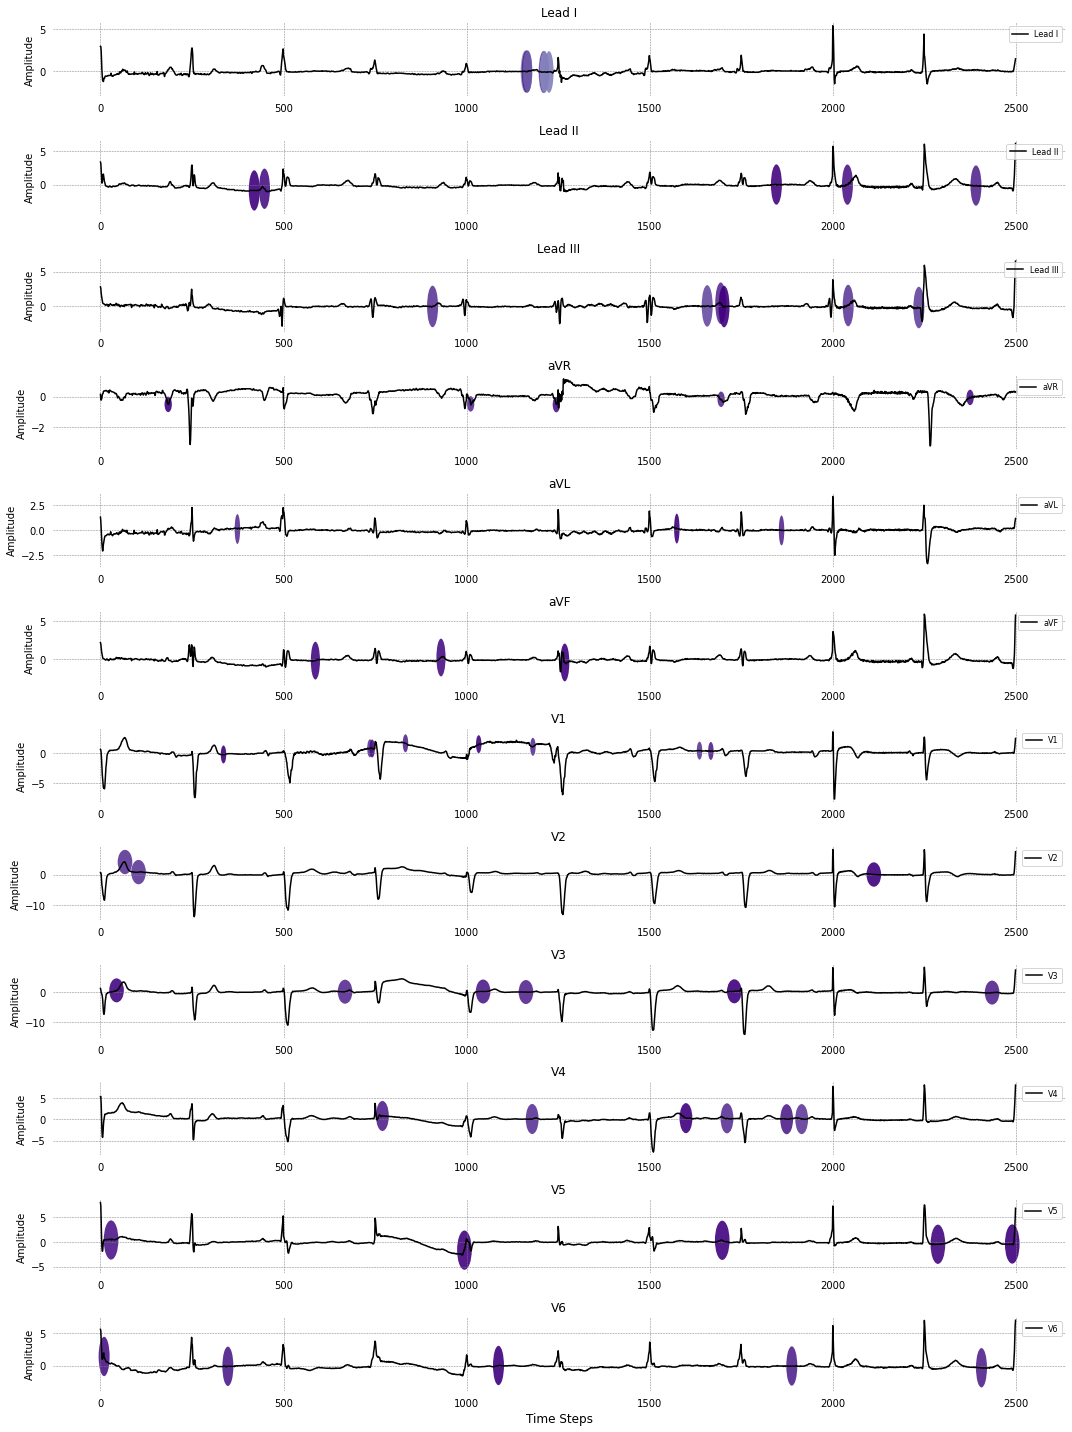

In [66]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

pooled_coefficients = lime_explanation(model= loaded_model_ecg, data = zero_ecg_final, pool_channels=False,channels=False)
# Names of the 12 leads for annotation
lead_names = ["Lead I", "Lead II", "Lead III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

# Function to adjust coefficients based on thresholds
def adjust_coefficients(coefficients, pos_threshold=0.0005, neg_threshold=-0.0005):
    """
    Adjust coefficients based on specified thresholds.
    
    Args:
    - coefficients: Original coefficients dict with 12 leads each having 2500 coefficients.
    - pos_threshold: Positive threshold.
    - neg_threshold: Negative threshold.
    
    Returns:
    - Adjusted coefficients.
    """
    adjusted_coeffs = {}
    for lead in coefficients:
        adjusted = np.zeros_like(coefficients[lead])
        adjusted[coefficients[lead] >= pos_threshold] = coefficients[lead][coefficients[lead] >= pos_threshold]
        adjusted[coefficients[lead] <= neg_threshold] = coefficients[lead][coefficients[lead] <= neg_threshold]
        adjusted_coeffs[lead] = adjusted
    return adjusted_coeffs

# Function to plot the original ECG and filtered coefficients as ellipses
def plot_ecg_with_ellipses(ecg_data, coefficients, lead_names, pos_threshold=0.0002, neg_threshold=-0.0002):
    """
    Plot the original ECG data with filtered coefficients as ellipses.

    Args:
    - ecg_data: Original ECG data, shaped (2500, 12).
    - coefficients: Coefficients for each lead, shaped as a dict with 12 leads each having 2500 coefficients.
    - lead_names: List of lead names.
    - pos_threshold: Positive threshold for filtering coefficients.
    - neg_threshold: Negative threshold for filtering coefficients.
    """
    # Adjust coefficients based on thresholds
    adjusted_coefficients = adjust_coefficients(coefficients, pos_threshold, neg_threshold)

    time_steps = ecg_data.shape[0]
    num_leads = ecg_data.shape[1]

    fig, axes = plt.subplots(num_leads, 1, figsize=(15, 20), sharex=True)

    for lead in range(num_leads):
        ax = axes[lead]
        ax.plot(ecg_data[:, lead], label=lead_names[lead], color='black')
        
        # Remove borders between leads
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.tick_params(axis='both', which='both', bottom=False, top=False, labelbottom=True, left=False, right=False, labelleft=True)

        # Notebook paper background style
        ax.grid(True, linestyle='--', color='gray', linewidth=0.5)

        # Get adjusted coefficients for the current lead
        filtered_coefficients = adjusted_coefficients[lead]

        # Normalize coefficients for color mapping
        if np.max(filtered_coefficients) != 0:
            norm_coefficients = filtered_coefficients / np.max(np.abs(filtered_coefficients))



            # Plot ellipses for coefficients
            for idx in range(time_steps):
                if filtered_coefficients[idx] != 0:
                    width = 5*int(np.max(ecg_data[:, lead])) if int(np.max(ecg_data[:, lead])) >=3 else 20
                    height = int(np.max(ecg_data[:, lead])) if int(np.max(ecg_data[:, lead])) >=3 else 1
                    color_intensity = plt.cm.Purples(np.abs(norm_coefficients[idx]))  # Using Purples colormap
                    ellipse = patches.Ellipse((idx, ecg_data[idx, lead]), width=width , height=height,
                                              color=color_intensity, alpha=0.9)

                    ellipse.set_edgecolor('none')  # Remove borders
                    ax.add_patch(ellipse)

        ax.set_title(lead_names[lead], fontsize=12)
        ax.set_ylabel('Amplitude', fontsize=10)
        ax.legend(loc='upper right', fontsize=8)

    plt.xlabel('Time Steps', fontsize=12)
    plt.tight_layout()
    plt.show()

# Example usage:s
# Assuming ecg_of_one_final is shaped (2500, 12) and pooled_coefficients is the dict with coefficients
plot_ecg_with_ellipses(zero_ecg_final, pooled_coefficients, lead_names)


In [ ]:
test_dataset_ecg = DataGeneratorECG(ecg_of_zero_final, np.array([0.0]).astype(np.float32), batch_size=1, shuffle=False)

model_path = 'pretrain_models/model_Resnet_50_ecg.h5'

# Load the model and provide the custom loss function in the custom_objects parameter
loaded_model_ecg = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})
predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

1/1 [==============================] - 1s 1s/step


In [61]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()



def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
          ecg = np.load(f)
          a,b,c = ecg.shape
          scaler.fit(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = scaler.transform(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = np.squeeze(ecg.reshape((c,a,b)))

    return ecg
def process_data_with_vars(test_cv, col):
    test_ECG_path = test_cv["npy_path"].values.tolist()
    label = test_cv["LTVA01"]
    test_features = np.array(test_cv[col].values,dtype= np.float32)
    test___data__ = np.empty([len(test_ECG_path),2500,12])
    for i, path in enumerate(test_ECG_path):
        test___data__[i,:,:] = load_and_preprocess_ecg(path)
    return test___data__, test_features,label

def process_data(test_cv):
    test_ECG_path = test_cv["npy_path"].values.tolist()
    label = test_cv["LTVA01"]
    test___data__ = np.empty([len(test_ECG_path),2500,12])
    for i, path in enumerate(test_ECG_path):
        test___data__[i,:,:] = load_and_preprocess_ecg(path)
    return test___data__, label
    


In [66]:
def results_():
    result = {}
    result_df = test_cv.groupby("MRN").tail(1)
    result_df = result_df.groupby("MRN").filter(lambda x: len(x) == 1)
    test___data__,t_f, t_y = process_data_with_vars(result_df,col)
    test_dataset_ecg_with_vars = DataGenerator(test___data__, t_f,np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
    predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)
    
    test___data__, t_y = process_data(result_df)
    test_dataset_ecg = DataGeneratorECG(test___data__, np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
    predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

    #X_rf = result_df[train_CV.columns[4:13]]
    #clf_rf = load('dataset/random_forest_classifier.joblib')
    #rf_prediction = clf_rf.predict_proba(X_rf)[:, 1]

    predictions = pred_final(predictions_ECG=predictions_ECG,predictions_ECG_with_Var=predictions_ECG_with_Var)
    return  predictions,t_y,result_df

In [67]:
predictions,t_y,result_df = results_()

1/1 [==============================] - 0s 119ms/step


Confusion Matrix:


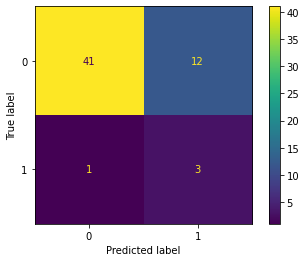


Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.77      0.86        53
           1       0.20      0.75      0.32         4

    accuracy                           0.77        57
   macro avg       0.59      0.76      0.59        57
weighted avg       0.92      0.77      0.82        57


Sensitivity (Recall): 0.7500
Specificity: 0.7736

 PPV : 0.2000
NPV : 0.9762


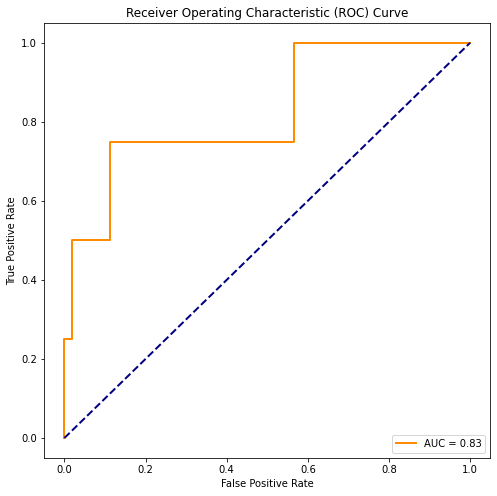

In [68]:
plot_results(predictions,test_label= result_df["LTVA01"])

In [91]:
result_df.shape

(73, 54)

In [68]:

def show_results_(r = 5):
    result = {}
    number_of_patients = []
    for i in range(1,r+1):
        result_df = test_cv.groupby("MRN").tail(i)
        result_df = result_df.groupby("MRN").filter(lambda x: len(x) == i)
        number_p = len(result_df['MRN'].unique())
        
        number_of_patients.append(number_p)


        test___data__,t_f, t_y = process_data_with_vars(result_df,col)
        test_dataset_ecg_with_vars = DataGenerator(test___data__, t_f,np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)
        
        test___data__, t_y = process_data(result_df)
        test_dataset_ecg = DataGeneratorECG(test___data__, np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

        #X_rf = result_df[train_CV.columns[4:13]]
        #clf_rf = load('dataset/random_forest_classifier.joblib')
        #rf_prediction = clf_rf.predict_proba(X_rf)[:, 1]

        predictions = pred_final(predictions_ECG=predictions_ECG,predictions_ECG_with_Var=predictions_ECG_with_Var)
        
        #label = [float(i[0]) for i in y_true]
        result_df["predictions"] = predictions
        #df_prediction = pd.concat([result_df["MHI MRN"],result_df["predictions"],result_df['Fam_positive_strict'] ],axis=1)
        mean_df = result_df.groupby("MRN").mean()
        predictions = mean_df["predictions"].values.tolist()
        predictions =np.array(predictions)
        t_y = mean_df["LTVA01"].values.tolist()
        fpr, tpr, thresholds = roc_curve(t_y, predictions)
        roc_auc = auc(fpr, tpr)
        result[i] = roc_auc
    data__ = {"ECGs_to_select": list(result.keys()),"AUC  test Patients Level":list(result.values()),"number_of_patients":number_of_patients}
    return pd.DataFrame(data__)
r_df = show_results_(r = 6)

r_df.head()



1/1 [==============================] - 0s 116ms/step


1/1 [==============================] - 0s 162ms/step


,ECGs_to_select,AUC test Patients Level,number_of_patients
0,1,0.825472,57
1,2,0.851190,46
2,3,0.885714,39
3,4,0.929688,36
4,5,0.869565,27


In [69]:
r_df.head(10)

,ECGs_to_select,AUC test Patients Level,number_of_patients
0,1,0.825472,57
1,2,0.851190,46
2,3,0.885714,39
3,4,0.929688,36
4,5,0.869565,27
5,6,0.883333,23


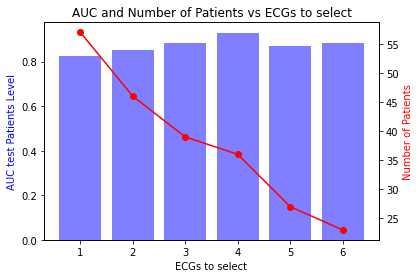

In [70]:
fig, ax1 = plt.subplots()

# Plot AUC on primary y-axis
ax1.bar(r_df['ECGs_to_select'], r_df['AUC  test Patients Level'], color='b', alpha=0.5)
ax1.set_xlabel('ECGs to select')
ax1.set_ylabel('AUC test Patients Level', color='b')

# Create secondary y-axis for number of patients
ax2 = ax1.twinx()
ax2.plot(r_df['ECGs_to_select'], r_df['number_of_patients'], color='r', marker='o')
ax2.set_ylabel('Number of Patients', color='r')

# Show plot
plt.title('AUC and Number of Patients vs ECGs to select')
plt.show()